(c) Simulate a Hebbian network with N = 500 for α = 0.02, 0.06, . . . , 0.62. For each α draw a pattern set, and mea- sure the fraction of unstable bits, ξμi hμi < 0 over all i and μ, and compare it with Φ(−1/√α). Then test recall: start from a stored pattern with 10% of its bits flipped, update asynchronously in random order until a full sweep changes nothing, and record the overlap m =(1/N)ξμ· s with the original. Average over 10 cues per α, plot <m> against α, and say where recall breaks down.

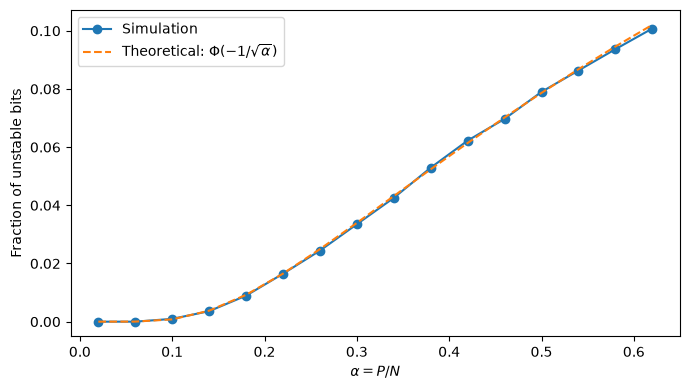

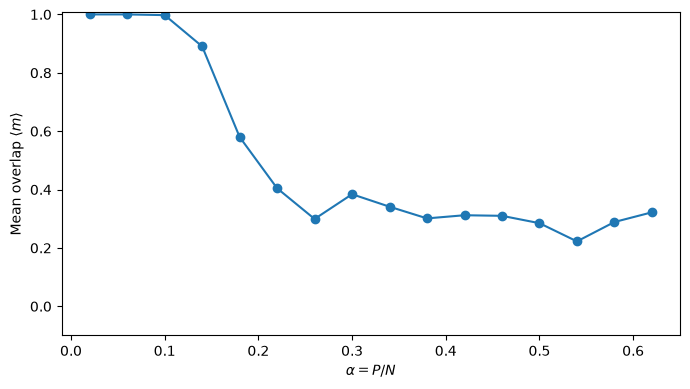

alpha = 0.0200, mean overlap = 1.0000
alpha = 0.0600, mean overlap = 1.0000
alpha = 0.1000, mean overlap = 0.9976
alpha = 0.1400, mean overlap = 0.8904
alpha = 0.1800, mean overlap = 0.5800
alpha = 0.2200, mean overlap = 0.4044
alpha = 0.2600, mean overlap = 0.2992
alpha = 0.3000, mean overlap = 0.3840
alpha = 0.3400, mean overlap = 0.3412
alpha = 0.3800, mean overlap = 0.3012
alpha = 0.4200, mean overlap = 0.3120
alpha = 0.4600, mean overlap = 0.3100
alpha = 0.5000, mean overlap = 0.2848
alpha = 0.5400, mean overlap = 0.2224
alpha = 0.5800, mean overlap = 0.2888
alpha = 0.6200, mean overlap = 0.3220


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr

# Parameters
N = 500
alpha_values = np.arange(0.02, 0.64, 0.04)
n_cues = 10
rng = np.random.default_rng(0)

unstable_fractions = []
theoretical_fractions = []
mean_overlaps = []

for a in alpha_values:
    P = round(a * N)
    patterns = rng.choice([-1, 1], size = (N, P))
    W = patterns @ patterns.T / N
    np.fill_diagonal(W, 0)

    # fraction of unstable bits in the patterns
    fields = W @ patterns
    unstable = patterns * fields < 0
    unstable_fractions.append(np.mean(unstable))

    # theoretical prediction
    theoretical_fractions.append(ndtr(-1 / np.sqrt(a)))

    # record the overlaps
    overlaps = []
    for c in range(n_cues):
        mu = rng.integers(P)
        target = patterns[:, mu].copy()

        # 10% of bits start flipped
        cue = target.copy()
        flip_bit = rng.choice(N, size = round(0.1 * N), replace = False)
        cue[flip_bit] *= -1
        s = cue.copy()

        # Update asynchronously
        while True:
            changed = False

            for i in rng.permutation(N):
                h = W[i] @ s
                new_state = 1 if h >= 0 else -1

                if new_state != s[i]:
                    s[i] = new_state
                    changed = True

            if not changed:
                break

        overlaps.append(np.dot(target, s) / N)
    
    mean_overlaps.append(np.mean(overlaps))

# plots
plt.figure(figsize = (7, 4))
plt.plot(alpha_values, unstable_fractions, "o-", label = "Simulation")
plt.plot(alpha_values, theoretical_fractions, "--", label = r"Theoretical: $\Phi(-1/\sqrt{\alpha})$")
plt.xlabel(r"$\alpha = P/N$")
plt.ylabel("Fraction of unstable bits")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize = (7, 4))
plt.plot(alpha_values, mean_overlaps, "o-")
plt.xlabel(r"$\alpha = P/N$")
plt.ylabel(r"Mean overlap $\langle m \rangle$")
plt.ylim(-0.1, 1.01)
plt.tight_layout()
plt.show()

for a, overlap in zip(alpha_values, mean_overlaps):
    print(f"alpha = {a:.4f}, mean overlap = {overlap:.4f}")